In [1]:
import numpy as np
from matplotlib import pyplot as plt

In [40]:
n = 1000
n_hidden = 64
Wrec_free = np.random.randn(n, n_hidden, n_hidden)/np.sqrt(n_hidden)

# Wrec_free = np.random.randn(n, n_hidden, n_hidden) * 1.5
# Wrec_free = np.random.uniform(-1, 1, size=(n, n_hidden, n_hidden))
# Wrec_free = np.random.exponential(scale=1/np.sqrt(n_hidden), size=(n, n_hidden, n_hidden))
def relu(x):
    return np.where(x > 0, x, 0)
def absolute(x):
    return np.where(x > 0, x, -x)
filter = relu
# eimask_logit = np.random.randint(0,2, size=(n, n_hidden)) * 2 - 1
eimask_logit = np.random.choice([0, 1], size=(n, n_hidden), p=[0.5, 0.5]) * 2 - 1
### transfer logit to diagonal matrix
relu_weight = filter(Wrec_free)
relu_eigvals = np.linalg.eigvals(relu_weight)
relu_real_parts = np.real(relu_eigvals)
relu_imag_parts = np.imag(relu_eigvals)

corrected_weight = np.array([filter(Wrec_free[i]) @ np.diag(eimask_logit[i]) for i in range(n)])
### calculate distribution of eigenvalues
eigvals_eisep = np.linalg.eigvals(corrected_weight)
real_parts_eisep = np.real(eigvals_eisep)
imag_parts_eisep = np.imag(eigvals_eisep)


# Wrec_simple = filter(Wrec_free.copy()) * np.where(np.random.rand(n, n_hidden, n_hidden) > 0.5, 1, -1)
Wrec_simple = Wrec_free.copy()
# Wrec_simple = np.random.randn(n, n_hidden, n_hidden) * 1.5
# Wrec_simple = np.random.uniform(-1, 1, size=(n, n_hidden, n_hidden))
eigvals_simple = np.linalg.eigvals(Wrec_simple)
real_parts_simple = np.real(eigvals_simple)
imag_parts_simple = np.imag(eigvals_simple)

In [36]:
Wrec_gamma = np.random.gamma(2,0.005, (n, n_hidden, n_hidden))
rho_gamma = np.max(np.abs(np.linalg.eigvals(Wrec_gamma)), axis=-1)
# print(rho_gamma)
Wrec_gamma_shrink = Wrec_gamma/rho_gamma.reshape(n,1,1) * 1.5
eimask_logit = np.random.choice([0, 1], size=(n, n_hidden), p=[0.2, 0.8]) * 2 - 1
gamma_weight = np.array([Wrec_gamma_shrink[i] @ np.diag(eimask_logit[i]) for i in range(n)])
eigvals_gamma = np.linalg.eigvals(gamma_weight)
real_parts_gamma = np.real(eigvals_gamma)
imag_parts_gamma = np.imag(eigvals_gamma)

In [37]:
Wrec_uniform = np.random.uniform(0,1/np.sqrt(n), (n, n_hidden, n_hidden))
# rho_gamma = np.max(np.abs(np.linalg.eigvals(Wrec_gamma)), axis=-1)
# print(rho_gamma)
# Wrec_gamma_shrink = Wrec_gamma/rho_gamma.reshape(n,1,1) * 1.5
# eimask_logit = np.random.choice([0, 1], size=(n, n_hidden), p=[0.2, 0.8]) * 2 - 1
dbpn_weight = np.array([Wrec_uniform[i] @ np.diag(eimask_logit[i]) for i in range(n)])
eigvals_dbpn = np.linalg.eigvals(dbpn_weight)
real_parts_dbpn = np.real(eigvals_dbpn)
imag_parts_dbpn = np.imag(eigvals_dbpn)

In [44]:
weights = [corrected_weight, Wrec_simple, gamma_weight, dbpn_weight]
names = ['EISep', 'Simple', 'DBPN', 'Song']
colors = ['C1', 'C0', 'C2', 'C3']

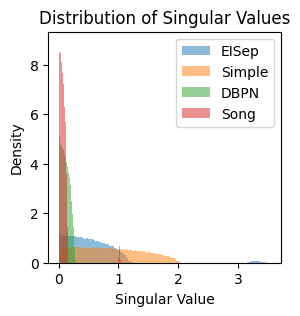

In [45]:
fig, ax = plt.subplots(1, 1, figsize=(3,3))
for i, weight in enumerate(weights):
    singular_value = np.linalg.svd(weight, compute_uv=False)
    ax.hist(singular_value.flatten(), bins=100, density=True, alpha=0.5, label=names[i])
ax.set_title('Distribution of Singular Values')
ax.set_xlabel('Singular Value')
ax.set_ylabel('Density')
ax.legend()
plt.show()

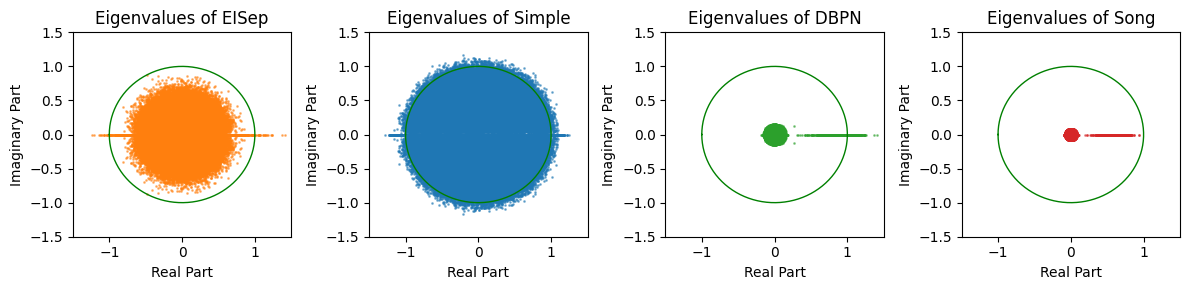

In [46]:
fig, ax = plt.subplots(1, len(eigvals), figsize=(3*len(eigvals), 3))
xs = np.linspace(-np.pi, np.pi, 100)
cosxs = np.cos(xs)
sinxs = np.sin(xs)
for i, weight in enumerate(weights):
    eigval = np.linalg.eigvals(weight)
    real_part = np.real(eigval)
    imag_part = np.imag(eigval)
    ax[i].scatter(real_part, imag_part, s=1, alpha=0.5, color=colors[i])
    ax[i].set_title(f'Eigenvalues of {names[i]}')
    ax[i].set_xlabel('Real Part')
    ax[i].set_ylabel('Imaginary Part')
    ax[i].set_xlim([-1.5, 1.5])
    ax[i].set_ylim([-1.5, 1.5])
    ax[i].plot(cosxs, sinxs, color='g', linewidth=1, linestyle='-', label='Unit Circle')
plt.tight_layout()
plt.show()

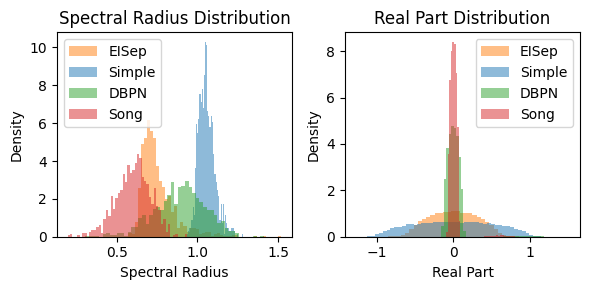

In [47]:
spectral_radius_ei = np.max(np.abs(eigvals_eisep), -1)
spectral_radius_simple = np.max(np.abs(eigvals_simple), -1)
spectral_radius_dbpn = np.max(np.abs(eigvals_dbpn), -1)
spectral_radiu_gamma = np.max(np.abs(eigvals_gamma), -1)

fig, ax = plt.subplots(1, 2, figsize=(6, 3))
for i, weight in enumerate(weights):
    eigval = np.linalg.eigvals(weight)
    spectral_radius = np.max(np.abs(eigval), -1)
    ax[0].hist(spectral_radius, bins=50, alpha=0.5, label=names[i], color=colors[i], density=True)
    real_part = np.real(eigval)
    ax[1].hist(real_part.flatten(), bins=50, alpha=0.5, label=names[i], color=colors[i], density=True)

ax[0].set_title('Spectral Radius Distribution')
ax[0].set_xlabel('Spectral Radius')
ax[0].set_ylabel('Density')
ax[0].legend()
ax[1].set_title('Real Part Distribution')
ax[1].set_xlabel('Real Part')
ax[1].set_ylabel('Density')
ax[1].legend()
plt.tight_layout()
plt.show()

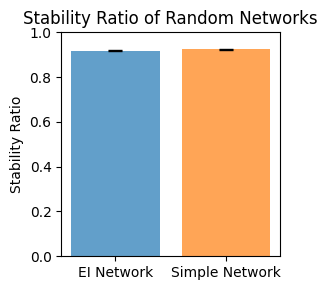

In [7]:
def is_stable(W):
    det = np.linalg.det(W)
    trace = np.trace(W, axis1=1, axis2=2)
    return (np.abs(det) < 1) & (1+det>np.abs(trace))
ei_stable = is_stable(corrected_weight)
simple_stable = is_stable(Wrec_simple)
ei_stable_mean = np.mean(ei_stable)
simple_stable_mean = np.mean(simple_stable)
ei_stable_std = np.std(ei_stable)/np.sqrt(n)
simple_stable_std = np.std(simple_stable)/np.sqrt(n)
fig, ax = plt.subplots(1, 1, figsize=(3,3))
ax.bar(['EI Network', 'Simple Network'], [ei_stable_mean, simple_stable_mean],
       yerr=[ei_stable_std, simple_stable_std], color=['C0', 'C1'], alpha=0.7)
ax.errorbar(['EI Network', 'Simple Network'], [ei_stable_mean, simple_stable_mean],
            yerr=[ei_stable_std, simple_stable_std], fmt='none', capsize=5, color='black')
ax.set_title('Stability Ratio of Random Networks')
ax.set_ylabel('Stability Ratio')
ax.set_ylim(0, 1)
plt.tight_layout()
plt.show()